# 01 - Data Preprocessing

Prepares the CheXpert dataset for training:
1. Filters to frontal-view X-rays only
2. Applies U-Ones uncertainty mapping (-1 mapped to 1)
3. Creates train/validation/test CSV files
4. Generates noise-injected label CSVs for all experimental conditions
5. Validates file paths and label integrity

## 1. Configuration and Paths

In [1]:
import os
import gc
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
import torch

from torch.utils.data import Dataset
from torchvision import transforms
from matplotlib.patches import Rectangle

SEED = 132
np.random.seed(SEED)

In [2]:
RAW_DIR = os.path.join('..', 'data', 'raw')
PROCESSED_DIR = os.path.join('..', 'data', 'processed')
TEST_DIR = os.path.join('..', 'data', 'test')
FIGURES_DIR = os.path.join('..', 'results','figures')
os.makedirs(PROCESSED_DIR, exist_ok=True)

train_raw = pd.read_csv(os.path.join(RAW_DIR, 'train.csv'))
val_raw = pd.read_csv(os.path.join(RAW_DIR, 'valid.csv'))
test_raw = pd.read_csv(os.path.join(TEST_DIR, 'test_labels.csv'))

print(f"Raw train: {train_raw.shape}")
print(f"Raw valid: {val_raw.shape}")
print(f"Raw test:  {test_raw.shape}")

Raw train: (223414, 19)
Raw valid: (234, 19)
Raw test:  (668, 15)


## 2. Load and Standardise Dataset Paths

Load the raw training, validation, and test metadata, then remove the dataset prefix from training and validation image paths so that paths can be resolved consistently during later processing.

In [ ]:
train_raw['Path'] = train_raw['Path'].str.replace('CheXpert-v1.0-small/', '', regex=False)
val_raw['Path'] = val_raw['Path'].str.replace('CheXpert-v1.0-small/', '', regex=False)

print(f"Sample train path: {train_raw['Path'].iloc[0]}")
print(f"Sample val path:   {val_raw['Path'].iloc[0]}")
print(f"Sample test path:  {test_raw['Path'].iloc[0]}")

Sample train path: train/patient00001/study1/view1_frontal.jpg
Sample val path:   valid/patient64541/study1/view1_frontal.jpg
Sample test path:  test/patient64741/study1/view1_frontal.jpg


## 3. Filter to Frontal Chest X-rays

Retain frontal-view images only. Training and validation metadata use the `Frontal/Lateral` field, while the test set is filtered using its path information.

In [4]:
# Train and val have a 'Frontal/Lateral' column
train_frontal = train_raw[train_raw['Frontal/Lateral'] == 'Frontal'].copy()
val_frontal = val_raw[val_raw['Frontal/Lateral'] == 'Frontal'].copy()

# Test set filters by path (no Frontal/Lateral column)
test_frontal = test_raw[test_raw['Path'].str.contains('frontal', case=False)].copy()

print(f"Frontal train: {train_frontal.shape[0]:,} (dropped {train_raw.shape[0] - train_frontal.shape[0]:,} lateral)")
print(f"Frontal valid: {val_frontal.shape[0]} (dropped {val_raw.shape[0] - val_frontal.shape[0]} lateral)")
print(f"Frontal test:  {test_frontal.shape[0]} (dropped {test_raw.shape[0] - test_frontal.shape[0]} lateral)")

Frontal train: 191,027 (dropped 32,387 lateral)
Frontal valid: 202 (dropped 32 lateral)
Frontal test:  518 (dropped 150 lateral)


## 4. Apply U-Ones Uncertainty Mapping

For the five target pathologies, missing labels are mapped to `0` and uncertain labels (`-1`) are mapped to `1`. The resulting labels are converted to binary integer values.

In [5]:
TARGET_PATHOLOGIES = [
    'Cardiomegaly',
    'Edema',
    'Consolidation',
    'Atelectasis',
    'Pleural Effusion'
]

def apply_u_ones(df, pathologies):
    df = df.copy()
    for col in pathologies:
        df[col] = df[col].fillna(0.0).replace(-1.0, 1.0).astype(int)
    return df

train_frontal = apply_u_ones(train_frontal, TARGET_PATHOLOGIES)
val_frontal = apply_u_ones(val_frontal, TARGET_PATHOLOGIES)
test_frontal = apply_u_ones(test_frontal, TARGET_PATHOLOGIES)

# Verify all values are 0/1
print("Unique values per pathology (should all be [0, 1]):")
for col in TARGET_PATHOLOGIES:
    print(f"  Train {col:20s}: {sorted(train_frontal[col].unique())}")
    print(f"  Test  {col:20s}: {sorted(test_frontal[col].unique())}")

Unique values per pathology (should all be [0, 1]):
  Train Cardiomegaly        : [np.int64(0), np.int64(1)]
  Test  Cardiomegaly        : [np.int64(0), np.int64(1)]
  Train Edema               : [np.int64(0), np.int64(1)]
  Test  Edema               : [np.int64(0), np.int64(1)]
  Train Consolidation       : [np.int64(0), np.int64(1)]
  Test  Consolidation       : [np.int64(0), np.int64(1)]
  Train Atelectasis         : [np.int64(0), np.int64(1)]
  Test  Atelectasis         : [np.int64(0), np.int64(1)]
  Train Pleural Effusion    : [np.int64(0), np.int64(1)]
  Test  Pleural Effusion    : [np.int64(0), np.int64(1)]


## 5. Inspect Example Images

Visualise representative positive and negative frontal chest X-rays for each target pathology as a basic qualitative check of the filtered dataset.

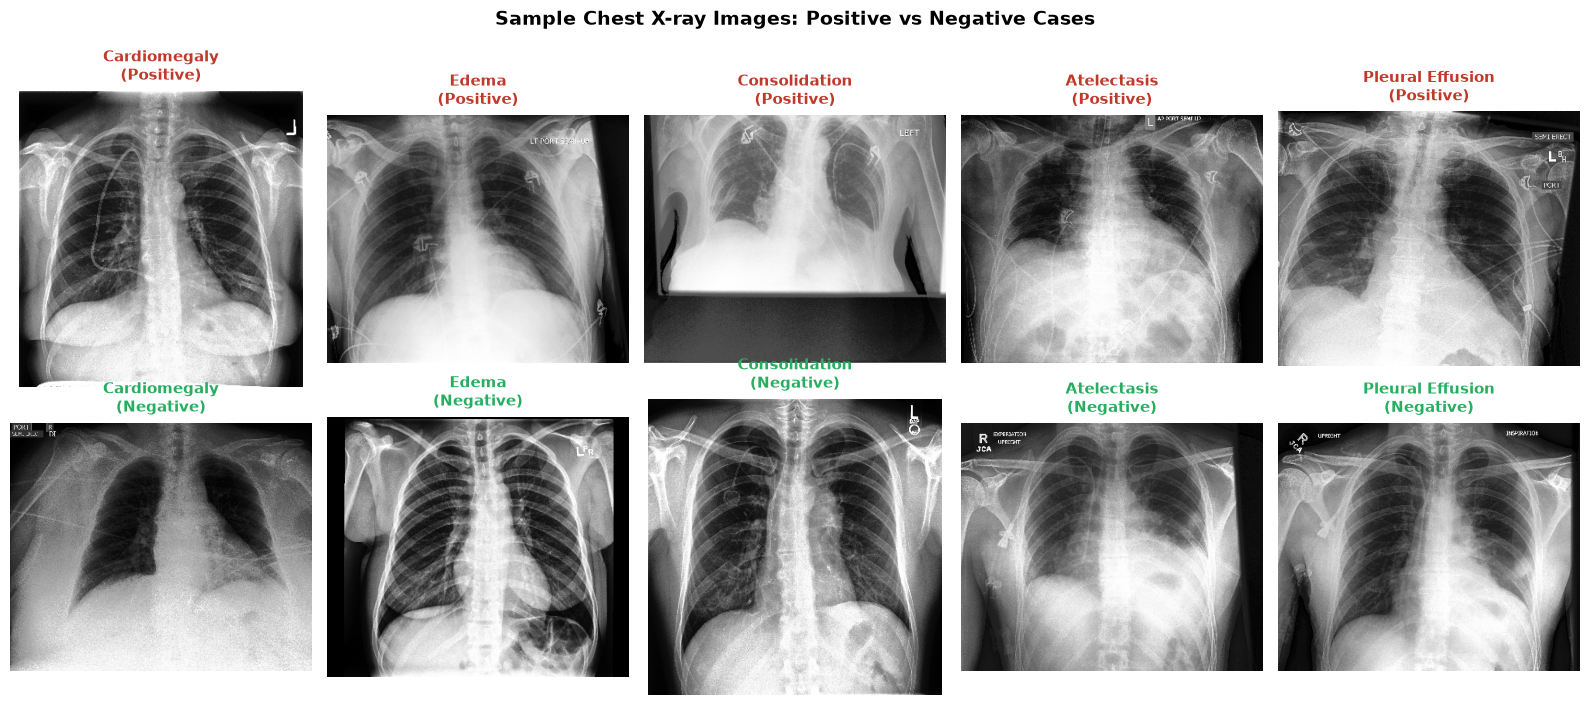

Saved: figA_sample_xrays.png/pdf


In [6]:
fig, axes = plt.subplots(2, 5, figsize=(16, 7))
 
for i, col in enumerate(TARGET_PATHOLOGIES):
    other_cols = [c for c in TARGET_PATHOLOGIES if c != col]
    
    pure_pos_mask = (train_frontal[col] == 1.0)
    for other in other_cols:
        pure_pos_mask = pure_pos_mask & (train_frontal[other] == 0.0)
    
    if pure_pos_mask.any():
        pos_row = train_frontal[pure_pos_mask].iloc[0]
    else:
        pos_row = train_frontal[train_frontal[col] == 1.0].iloc[0]
    
    pure_neg_mask = pd.Series([True] * len(train_frontal), index=train_frontal.index)
    for c in TARGET_PATHOLOGIES:
        pure_neg_mask = pure_neg_mask & (train_frontal[c] == 0.0)
    
    if pure_neg_mask.sum() > i:
        neg_row = train_frontal[pure_neg_mask].iloc[i]
    else:
        neg_row = train_frontal[train_frontal[col] == 0.0].iloc[0]
    
    for j, (row, label, color) in enumerate([(pos_row, "Positive", '#C0392B'),
                                              (neg_row, "Negative", '#27AE60')]):
        full_path = os.path.join(RAW_DIR, row['Path'])
        try:
            img = Image.open(full_path).convert('L')
            axes[j, i].imshow(img, cmap='gray')
        except Exception as e:
            axes[j, i].text(0.5, 0.5, 'Image\nnot found', ha='center', va='center',
                            transform=axes[j, i].transAxes, fontsize=10, color='red')
        
        axes[j, i].set_title(f'{col}\n({label})', fontsize=11,
                              color=color, fontweight='bold', pad=8)
        axes[j, i].axis('off')
 
plt.suptitle('Sample Chest X-ray Images: Positive vs Negative Cases',
             fontsize=14, y=1.00, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'figA_sample_xrays.png'), dpi=600, bbox_inches='tight')
plt.savefig(os.path.join(FIGURES_DIR, 'figA_sample_xrays.pdf'), bbox_inches='tight')
plt.show()
print("Saved: figA_sample_xrays.png/pdf")

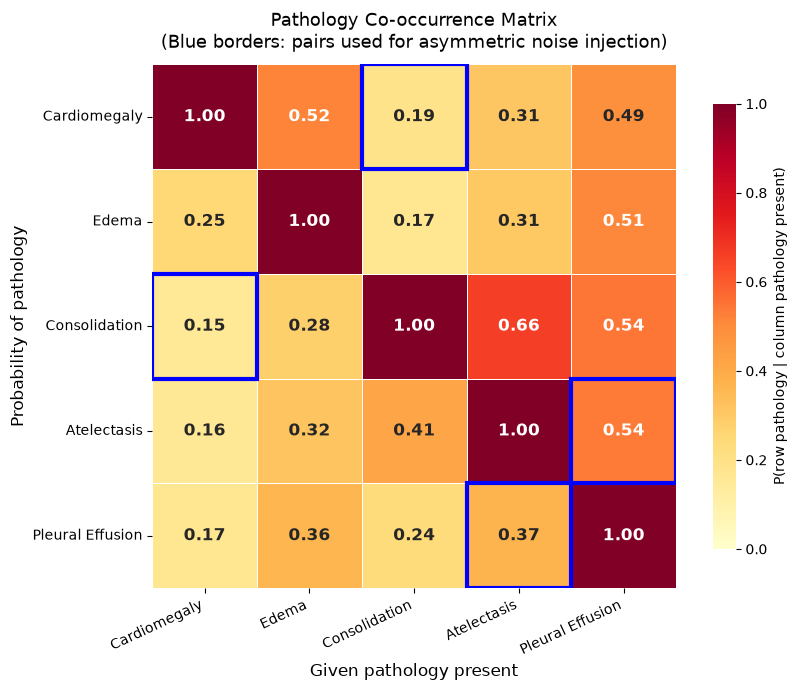

In [7]:
cooccurrence = train_frontal[TARGET_PATHOLOGIES].T.dot(train_frontal[TARGET_PATHOLOGIES])

diag = np.diag(cooccurrence).copy()
cooccurrence_norm = cooccurrence.div(diag, axis=0)

fig, ax = plt.subplots(figsize=(9, 7))
 
# Use a professional colormap
mask = np.zeros_like(cooccurrence_norm, dtype=bool)
sns.heatmap(
    cooccurrence_norm,
    annot=True,
    fmt='.2f',
    cmap='YlOrRd',
    cbar_kws={'label': 'P(row pathology | column pathology present)', 'shrink': 0.85},
    xticklabels=TARGET_PATHOLOGIES,
    yticklabels=TARGET_PATHOLOGIES,
    ax=ax,
    vmin=0, vmax=1,
    annot_kws={'fontsize': 12, 'fontweight': 'bold'},
    linewidths=0.5, linecolor='white',
    square=True
)
 
ax.add_patch(Rectangle((0, 2), 1, 1, fill=False, edgecolor='blue', lw=3))
ax.add_patch(Rectangle((2, 0), 1, 1, fill=False, edgecolor='blue', lw=3))
 
ax.add_patch(Rectangle((4, 3), 1, 1, fill=False, edgecolor='blue', lw=3))
ax.add_patch(Rectangle((3, 4), 1, 1, fill=False, edgecolor='blue', lw=3))
 
ax.set_title('Pathology Co-occurrence Matrix\n(Blue borders: pairs used for asymmetric noise injection)',
             fontsize=13, pad=12)
ax.set_xlabel('Given pathology present', fontsize=12)
ax.set_ylabel('Probability of pathology', fontsize=12)
 
plt.setp(ax.get_xticklabels(), rotation=25, ha='right')
plt.setp(ax.get_yticklabels(), rotation=0)
 
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'figB_cooccurrence.png'), bbox_inches='tight')
plt.savefig(os.path.join(FIGURES_DIR, 'figB_cooccurrence.pdf'), bbox_inches='tight')
plt.show()

## 6. Examine Class Imbalance

Compare positive and negative label counts across the five target pathologies to characterise the class distribution in the training data.


Counts:
  Cardiomegaly        : pos=30,092  neg=160,935
  Edema               : pos=61,493  neg=129,534
  Consolidation       : pos=37,364  neg=153,663
  Atelectasis         : pos=59,583  neg=131,444
  Pleural Effusion    : pos=86,477  neg=104,550


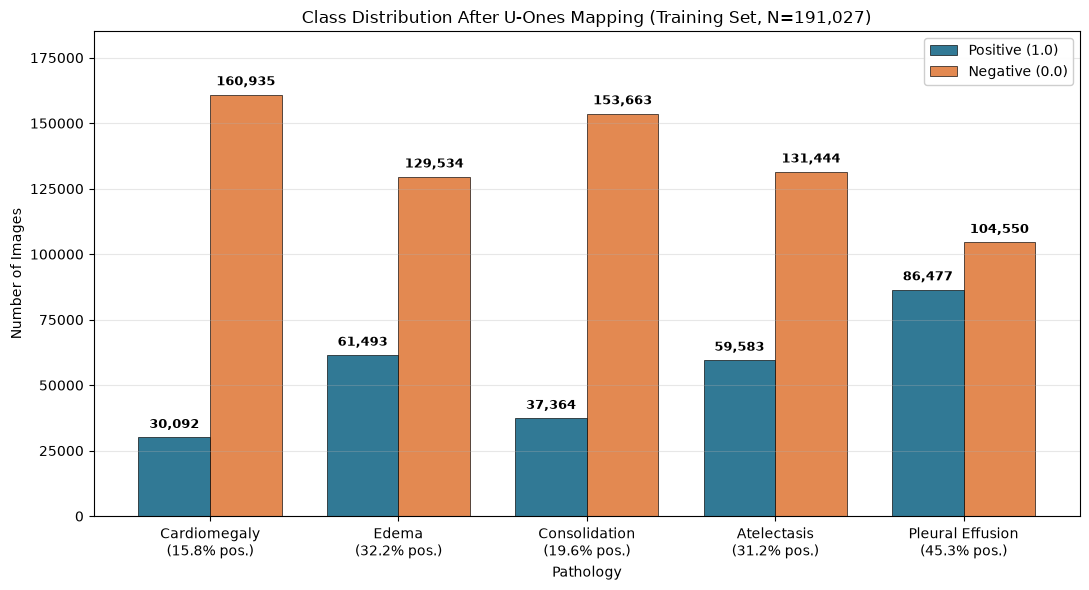

In [8]:
pos_counts = [int((train_frontal[col] == 1.0).sum()) for col in TARGET_PATHOLOGIES]
neg_counts = [int((train_frontal[col] == 0.0).sum()) for col in TARGET_PATHOLOGIES]

# Print for verification
print("\nCounts:")
for i, p in enumerate(TARGET_PATHOLOGIES):
    print(f"  {p:20s}: pos={pos_counts[i]:6,}  neg={neg_counts[i]:6,}")

fig, ax = plt.subplots(figsize=(11, 6))

x = np.arange(len(TARGET_PATHOLOGIES))
width = 0.38

bars_pos = ax.bar(x - width/2, pos_counts, width,
                   label='Positive (1.0)', color='#1A6B8A', alpha=0.90,
                   edgecolor='black', linewidth=0.5)
bars_neg = ax.bar(x + width/2, neg_counts, width,
                   label='Negative (0.0)', color='#E07C3E', alpha=0.90,
                   edgecolor='black', linewidth=0.5)

# Auto-scale label offset based on data range
y_max = max(max(pos_counts), max(neg_counts))
label_offset = y_max * 0.015

for bar in list(bars_pos) + list(bars_neg):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, height + label_offset,
            f'{int(height):,}', ha='center', va='bottom', fontsize=9, fontweight='bold')

total = len(train_frontal)
pos_rates = [pos / total * 100 for pos in pos_counts]
xtick_labels = [f'{p}\n({r:.1f}% pos.)' for p, r in zip(TARGET_PATHOLOGIES, pos_rates)]

ax.set_xlabel('Pathology')
ax.set_ylabel('Number of Images')
ax.set_title(f'Class Distribution After U-Ones Mapping (Training Set, N={total:,})')
ax.set_xticks(x)
ax.set_xticklabels(xtick_labels, fontsize=10)
ax.legend(loc='upper right', framealpha=0.95)
ax.grid(axis='y', alpha=0.3)
ax.set_ylim(0, y_max * 1.15)  # Enough headroom for labels

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'figC_class_distribution.png'), dpi=600, bbox_inches='tight')
plt.savefig(os.path.join(FIGURES_DIR, 'figC_class_distribution.pdf'), bbox_inches='tight')
plt.show()

## 7. Compare Label Prevalence Across Splits

Check the positive-label rates for the training, validation, and test sets.

In [9]:
print("=== Positive rates ===")
print(f"{'Pathology':<22}{'Train':>10}{'Val':>10}{'Test':>10}")
print("-" * 52)
for col in TARGET_PATHOLOGIES:
    tr = train_frontal[col].mean()
    vr = val_frontal[col].mean()
    te = test_frontal[col].mean()
    print(f"{col:<22}{tr:>10.3f}{vr:>10.3f}{te:>10.3f}")

=== Positive rates ===
Pathology                  Train       Val      Test
----------------------------------------------------
Cardiomegaly               0.158     0.327     0.297
Edema                      0.322     0.208     0.153
Consolidation              0.196     0.158     0.056
Atelectasis                0.312     0.371     0.305
Pleural Effusion           0.453     0.317     0.203


## 8. Create Final Dataset Splits and Check Patient Separation

Retain only image paths and the five target pathology labels, then verify that no patients overlap between the training, validation, and test splits.

In [10]:
KEEP_COLS = ['Path'] + TARGET_PATHOLOGIES

train_df = train_frontal[KEEP_COLS].reset_index(drop=True).copy()
val_df = val_frontal[KEEP_COLS].reset_index(drop=True).copy()
test_df = test_frontal[KEEP_COLS].reset_index(drop=True).copy()

# Verify no patient overlap between train and val
train_patients = set(train_df['Path'].str.extract(r'(patient\d+)')[0].unique())
val_patients = set(val_df['Path'].str.extract(r'(patient\d+)')[0].unique())
test_patients = set(test_df['Path'].str.extract(r'(patient\d+)')[0].unique())

print(f"Train: {len(train_df):,} images from {len(train_patients):,} patients")
print(f"Val:   {len(val_df)} images from {len(val_patients)} patients")
print(f"Test:  {len(test_df)} images from {len(test_patients)} patients")
print(f"\nTrain-Val patient overlap:  {len(train_patients & val_patients)} (should be 0)")
print(f"Train-Test patient overlap: {len(train_patients & test_patients)} (should be 0)")
print(f"Val-Test patient overlap:   {len(val_patients & test_patients)} (should be 0)")

Train: 191,027 images from 64,534 patients
Val:   202 images from 200 patients
Test:  518 images from 500 patients

Train-Val patient overlap:  0 (should be 0)
Train-Test patient overlap: 0 (should be 0)
Val-Test patient overlap:   0 (should be 0)


## 9. Validate Image Paths

Randomly sample image paths from each split to confirm that the corresponding files can be located in their expected data directories.

In [11]:
def check_paths(df, data_dir, name, n_check=100):
    sample = df['Path'].sample(min(n_check, len(df)), random_state=SEED)
    missing = 0
    for p in sample:
        full_path = os.path.join(data_dir, p)
        if not os.path.exists(full_path):
            missing += 1
            if missing <= 3:
                print(f"  Missing: {full_path}")
    print(f"{name}: {missing}/{len(sample)} missing in sample")
    return missing == 0

check_paths(train_df, RAW_DIR, 'Train')
check_paths(val_df, RAW_DIR, 'Val')
check_paths(test_df, TEST_DIR, 'Test')  # test uses TEST_DIR, not RAW_DIR!

Train: 0/100 missing in sample
Val: 0/100 missing in sample
Test: 0/100 missing in sample


True

## 10. Release Intermediate Data

Remove large intermediate DataFrames that are no longer required and report the memory footprint of the final split DataFrames.

In [12]:
for var in ['train_raw', 'val_raw', 'test_raw', 'train_frontal', 'val_frontal', 'test_frontal']:
    if var in dir():
        exec(f'del {var}')
gc.collect()

print(f"train_df memory: {train_df.memory_usage(deep=True).sum() / 1e6:.1f} MB")
print(f"val_df memory:   {val_df.memory_usage(deep=True).sum() / 1e6:.1f} MB")
print(f"test_df memory:  {test_df.memory_usage(deep=True).sum() / 1e6:.1f} MB")

train_df memory: 25.2 MB
val_df memory:   0.0 MB
test_df memory:  0.1 MB


## 11. Define Label Noise Injection Methods

Define the symmetric and asymmetric label-noise procedures used to generate the experimental training datasets.

- **Symmetric noise:** each pathology label is independently flipped with probability equal to the specified noise rate.
- **Asymmetric noise:** labels are transitioned between the predefined clinically related pathology pairs when one member of a pair is positive and the other is negative.

In [13]:
def inject_symmetric_noise(labels_df, pathologies, noise_rate, seed=None):
    """Flip each label independently with probability noise_rate."""
    rng = np.random.RandomState(seed)
    noisy_df = labels_df.copy()
    flip_counts = {}
    
    for col in pathologies:
        labels = noisy_df[col].values.copy()
        flip_mask = rng.random(len(labels)) < noise_rate
        labels[flip_mask] = 1 - labels[flip_mask]
        noisy_df[col] = labels
        flip_counts[col] = int(flip_mask.sum())
    
    return noisy_df, flip_counts


ASYMMETRIC_PAIRS = [
    ('Consolidation', 'Atelectasis'),
    ('Edema', 'Pleural Effusion'),
]


def inject_asymmetric_noise(labels_df, pairs, noise_rate, seed=None):
    """Flip labels between clinically similar pathology pairs."""
    rng = np.random.RandomState(seed)
    noisy_df = labels_df.copy()
    flip_counts = {}
    
    for col_a, col_b in pairs:
        labels_a = noisy_df[col_a].values.copy()
        labels_b = noisy_df[col_b].values.copy()
        n = len(labels_a)
        
        # A positive, B negative: possibly flip A->0, B->1
        flip_mask = rng.random(n) < noise_rate
        a_to_b = flip_mask & (labels_a == 1) & (labels_b == 0)
        labels_a[a_to_b] = 0
        labels_b[a_to_b] = 1
        
        # B positive, A negative: possibly flip B->0, A->1
        flip_mask_2 = rng.random(n) < noise_rate
        b_to_a = flip_mask_2 & (labels_b == 1) & (labels_a == 0)
        labels_b[b_to_a] = 0
        labels_a[b_to_a] = 1
        
        noisy_df[col_a] = labels_a
        noisy_df[col_b] = labels_b
        flip_counts[f"{col_a} <-> {col_b}"] = int(a_to_b.sum() + b_to_a.sum())
    
    return noisy_df, flip_counts

## 12. Generate and Save Experimental Datasets

Save the clean training, validation, and test splits, then generate deterministic symmetric and asymmetric noisy versions of the training labels at 5%, 10%, 20%, and 40% noise rates.

In [14]:
NOISE_RATES = [0.05, 0.10, 0.20, 0.40]

# Save clean splits
train_df.to_csv(os.path.join(PROCESSED_DIR, 'train_clean.csv'), index=False)
val_df.to_csv(os.path.join(PROCESSED_DIR, 'val_clean.csv'), index=False)
test_df.to_csv(os.path.join(PROCESSED_DIR, 'test_official.csv'), index=False)
print(f"Saved clean splits to {PROCESSED_DIR}")

# Generate symmetric noise variants
print("\n=== Symmetric Noise ===")
for rate in NOISE_RATES:
    noisy, counts = inject_symmetric_noise(train_df, TARGET_PATHOLOGIES, rate, seed=SEED)
    fname = f'train_symmetric_{int(rate*100):02d}.csv'
    noisy.to_csv(os.path.join(PROCESSED_DIR, fname), index=False)
    
    total_flips = sum(counts.values())
    total_labels = len(train_df) * len(TARGET_PATHOLOGIES)
    print(f"  {fname}: target={rate:.0%}, actual={total_flips/total_labels:.2%}, flips={total_flips:,}")
    
    del noisy
    gc.collect()

# Generate asymmetric noise variants
print("\n=== Asymmetric Noise ===")
for rate in NOISE_RATES:
    noisy, counts = inject_asymmetric_noise(train_df, ASYMMETRIC_PAIRS, rate, seed=SEED)
    fname = f'train_asymmetric_{int(rate*100):02d}.csv'
    noisy.to_csv(os.path.join(PROCESSED_DIR, fname), index=False)
    
    total_flips = sum(counts.values())
    print(f"  {fname}: target={rate:.0%}, flips={total_flips:,}")
    for pair, count in counts.items():
        print(f"    {pair}: {count:,} swaps")
    
    del noisy
    gc.collect()

print("\nAll CSVs generated.")

Saved clean splits to ..\data\processed

=== Symmetric Noise ===
  train_symmetric_05.csv: target=5%, actual=5.02%, flips=47,907
  train_symmetric_10.csv: target=10%, actual=10.01%, flips=95,620
  train_symmetric_20.csv: target=20%, actual=20.03%, flips=191,356
  train_symmetric_40.csv: target=40%, actual=40.06%, flips=382,630

=== Asymmetric Noise ===
  train_asymmetric_05.csv: target=5%, flips=6,808
    Consolidation <-> Atelectasis: 2,358 swaps
    Edema <-> Pleural Effusion: 4,450 swaps
  train_asymmetric_10.csv: target=10%, flips=13,813
    Consolidation <-> Atelectasis: 4,872 swaps
    Edema <-> Pleural Effusion: 8,941 swaps
  train_asymmetric_20.csv: target=20%, flips=28,482
    Consolidation <-> Atelectasis: 10,036 swaps
    Edema <-> Pleural Effusion: 18,446 swaps
  train_asymmetric_40.csv: target=40%, flips=60,165
    Consolidation <-> Atelectasis: 21,164 swaps
    Edema <-> Pleural Effusion: 39,001 swaps

All CSVs generated.


## 13. Verify Generated Outputs

List the processed CSV files and confirm the final target pathologies, noise rates, and asymmetric pathology pairs.

In [15]:
print("=== Files in processed directory ===")
for f in sorted(os.listdir(PROCESSED_DIR)):
    if f.endswith('.csv'):
        fpath = os.path.join(PROCESSED_DIR, f)
        df_tmp = pd.read_csv(fpath)
        print(f"  {f:40s} {df_tmp.shape[0]:>8,} rows")
        del df_tmp

print(f"\nTarget pathologies: {TARGET_PATHOLOGIES}")
print(f"Noise rates: {NOISE_RATES}")
print(f"Asymmetric pairs: {ASYMMETRIC_PAIRS}")

=== Files in processed directory ===
  test_official.csv                             518 rows
  train_asymmetric_05.csv                   191,027 rows
  train_asymmetric_10.csv                   191,027 rows
  train_asymmetric_20.csv                   191,027 rows
  train_asymmetric_40.csv                   191,027 rows
  train_clean.csv                           191,027 rows
  train_symmetric_05.csv                    191,027 rows
  train_symmetric_10.csv                    191,027 rows
  train_symmetric_20.csv                    191,027 rows
  train_symmetric_40.csv                    191,027 rows
  val_clean.csv                                 202 rows

Target pathologies: ['Cardiomegaly', 'Edema', 'Consolidation', 'Atelectasis', 'Pleural Effusion']
Noise rates: [0.05, 0.1, 0.2, 0.4]
Asymmetric pairs: [('Consolidation', 'Atelectasis'), ('Edema', 'Pleural Effusion')]
